In [1]:
import pandas as pd

In [17]:
df = pd.read_csv('biomet_data.csv')
cols = df.columns

In [18]:
df.shape

(143, 1)

In [19]:
len(df)

143

In [20]:
len(df.iloc[0, 0])         # the raw content of the first row's first (only) column
          

17000

In [21]:
each user has 10 images  and each one and total 100 users with 144 feature of each image

SyntaxError: invalid syntax (4202754804.py, line 1)

In [22]:
len(df.iloc[1].values[0].split('\t')) #each row consists of 1000 values seperated by \t 1001 us empty

1001

In [23]:
import numpy as np
def generate_feature_vector(x):
    return np.array(x.values[0].split('\t'))

In [24]:
new_df = df.iloc[:, 0].str.split('\t', expand=True)
print(new_df)

                 0                 1                 2                 3     \
0      3.6409315e+002    3.4858811e+002    3.3181183e+002    2.8980958e+002   
1      2.3910673e+002    2.3826485e+002    2.8961825e+002    1.7342357e+002   
2      2.0698782e+002    2.4155478e+002    2.8139093e+002    2.1913554e+002   
3      1.9214200e+002    2.1670194e+002    2.4503126e+002    2.1616553e+002   
4      3.3933542e+002    2.9216018e+002    3.3709025e+002    2.7294746e+002   
..                ...               ...               ...               ...   
138    1.4906571e+002    1.5316811e+002    1.6849079e+002    1.4721565e+002   
139    1.3648869e+002    1.5424074e+002    1.6917194e+002    1.5772283e+002   
140    1.3814310e+002    1.6082182e+002    1.6952535e+002    1.7764754e+002   
141    1.7101205e+002    1.8612079e+002    1.7506606e+002    1.8651449e+002   
142    1.6121722e+002    1.7102661e+002    1.7898578e+002    1.8268898e+002   

                 4                 5               

In [25]:
new_df = new_df.drop(new_df.columns[1000
],axis = 1)


In [26]:
new_df.shape

(143, 1000)

In [27]:
features= new_df.T

In [28]:
features.shape

(1000, 143)

In [29]:
X = np.array(features).reshape(100,10,143)

In [30]:
X.shape

(100, 10, 143)

In [31]:
X_train = X[:, :5, :]   # (100, 5, 143)
X_test  = X[:, 5:, :]   # (100, 5, 143)

In [32]:
X_train = X_train.astype(np.float64)
X_test = X_test.astype(np.float64)

In [33]:
X_train[0]

array([[364.09315, 239.10673, 206.98782, 192.142  , 339.33542, 378.60285,
        331.73323, 312.88632, 243.36447, 226.37477, 195.61846, 266.50523,
        349.31847, 253.19228, 283.1247 , 279.5288 , 338.73592, 346.62598,
        384.03447, 411.35408, 264.13458, 258.5022 , 220.95273, 190.34747,
        312.37355, 287.45229, 256.44232, 258.81305, 320.28307, 359.9693 ,
        395.87122, 382.39722, 225.46519, 214.84428, 187.26655, 142.09631,
        300.08896, 316.68489, 255.04807, 214.57589, 231.86913, 276.38243,
        274.46529, 245.77158, 237.12815, 179.85547, 147.90238, 188.76139,
        229.10197, 315.54127, 351.31583, 304.29648, 338.91175, 293.48144,
        214.79103, 195.98557, 217.21916, 182.14412, 151.3903 , 206.80735,
        216.61922, 270.63836, 349.11462, 284.53583, 377.96065, 396.51356,
        356.04293, 299.70089, 251.17748, 203.93872, 183.71152, 248.05531,
        211.05404, 190.89137, 247.18716, 212.61815, 215.52117, 248.46966,
        228.8105 , 287.62232, 306.4388

           SCORE INFORMATION
Genuine scores  : 500
Imposter scores : 49500

             EUCLIDEAN RESULTS
Mean Genuine      : 290.341004
Mean Imposter     : 701.145678
Std Genuine       : 135.242190
Std Imposter      : 301.430785
EER Threshold     : 427.295008
EER               : 11.8000%
Decidability d'   : 1.758477

              COSINE RESULTS
Mean Genuine      : 0.989529
Mean Imposter     : 0.960512
Std Genuine       : 0.010998
Std Imposter      : 0.018289
EER Threshold     : 0.979165
EER               : 8.2121%
Decidability d'   : 1.922918


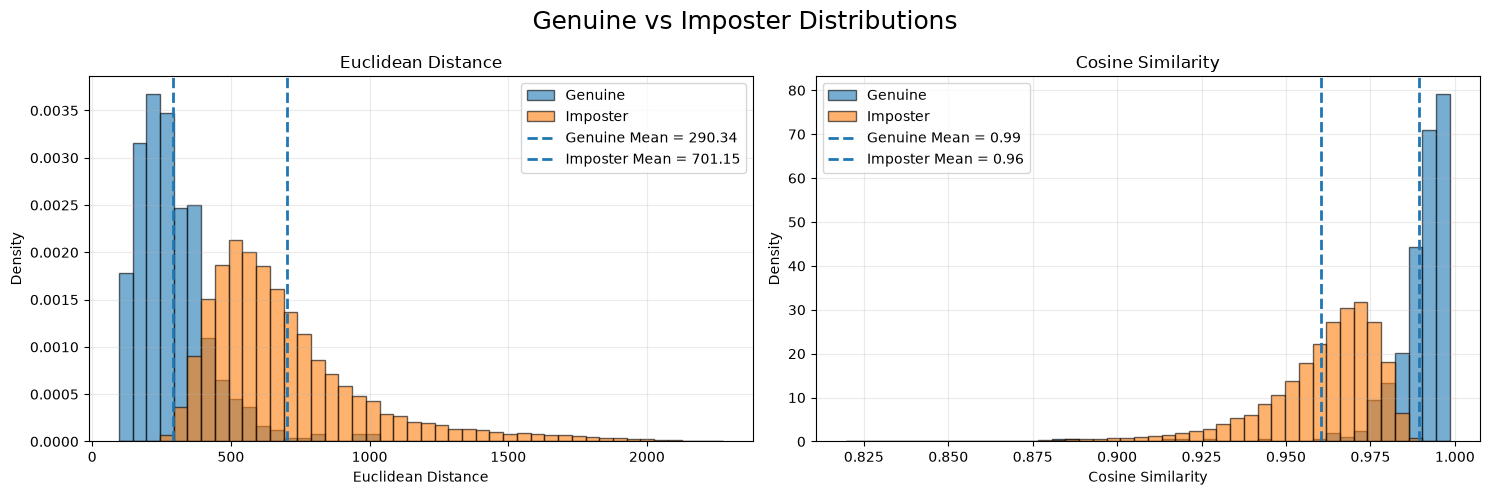

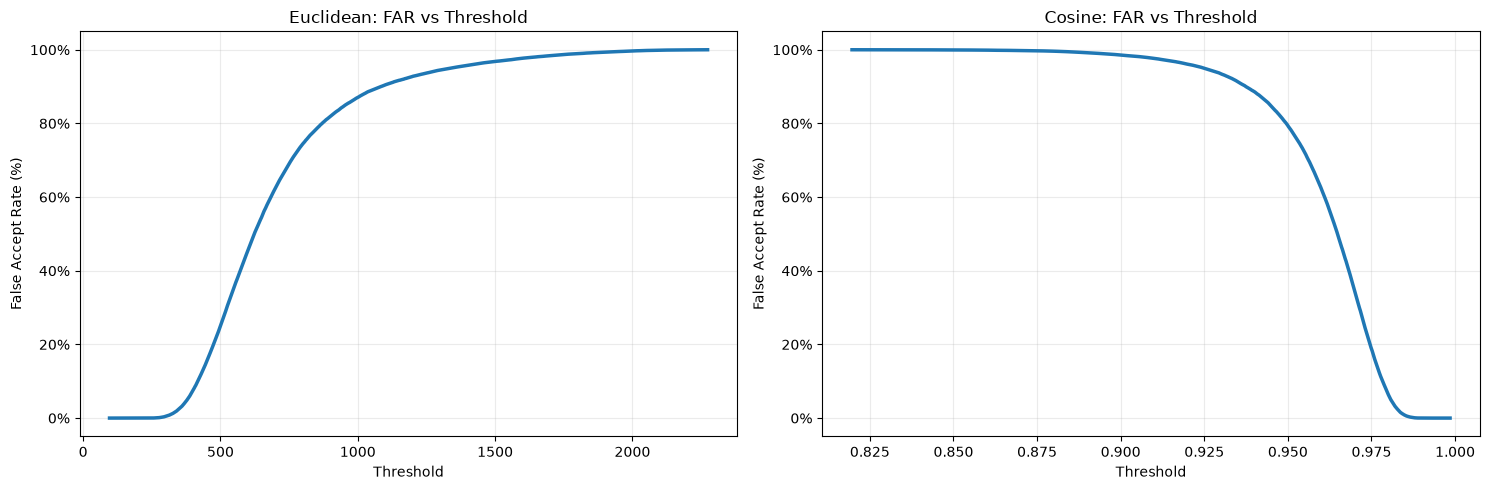

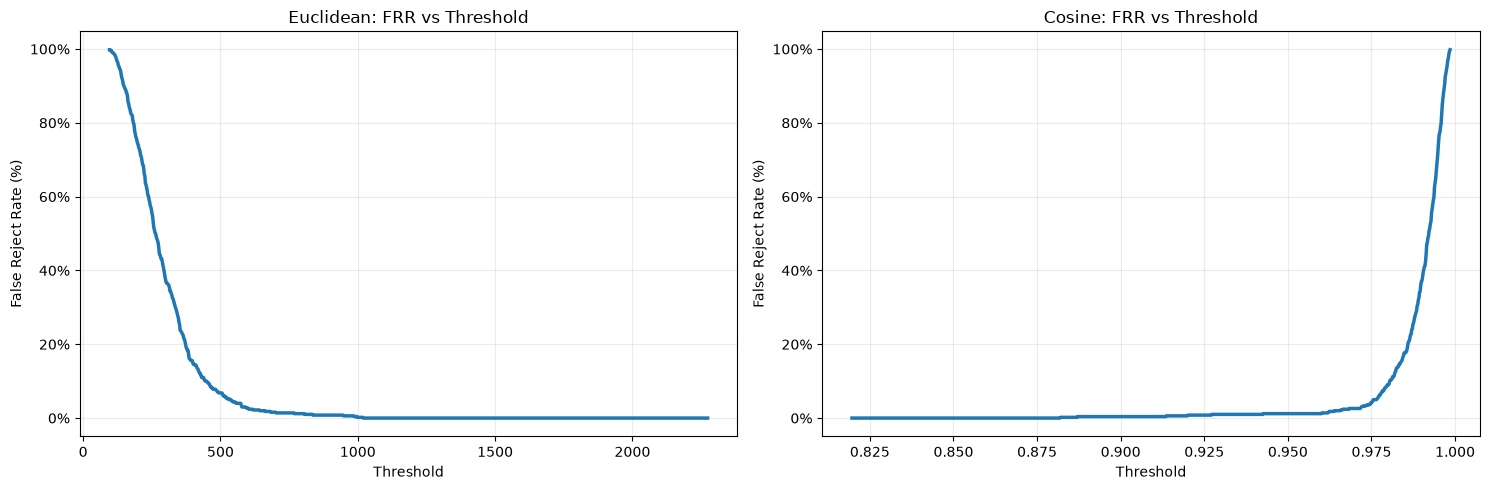

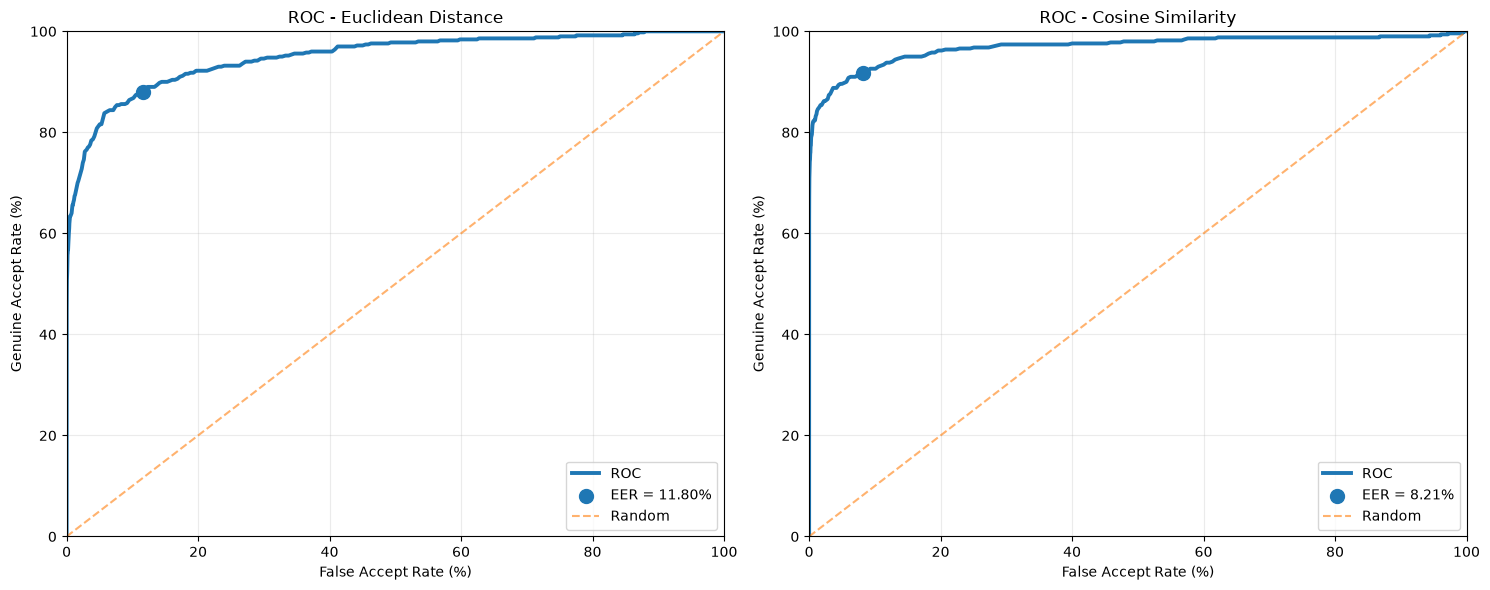

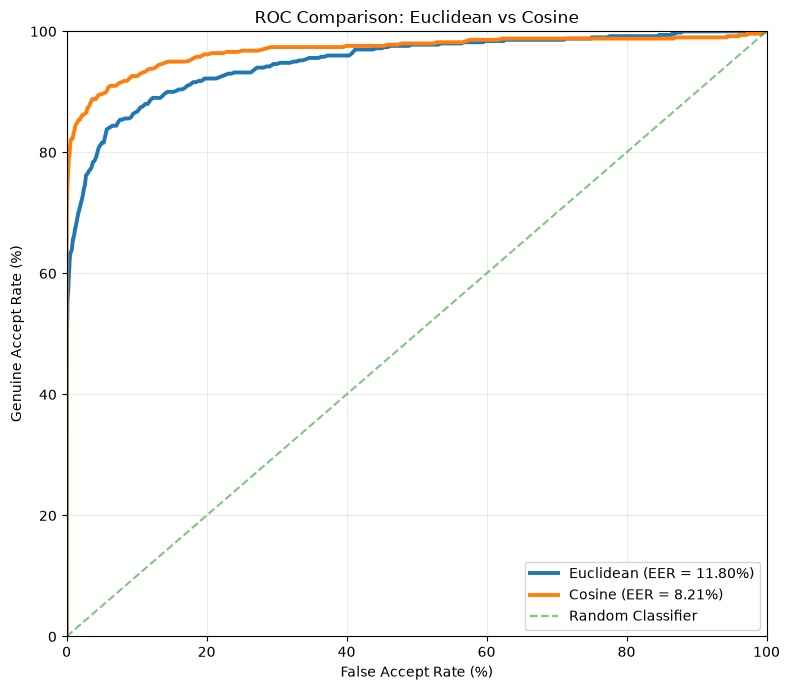


          EUCLIDEAN vs COSINE COMPARISON
Metric                         Euclidean         Cosine
------------------------------------------------------------
EER                             11.8000%        8.2121%
Decidability Index                1.7585         1.9229
Genuine Mean                    290.3410         0.9895
Imposter Mean                   701.1457         0.9605

Best matching criterion: COSINE SIMILARITY


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from matplotlib.ticker import PercentFormatter


# ==========================================================
# STEP 1 : CONVERT FEATURE VECTORS TO FLOAT
# ==========================================================

X_train = X_train.astype(np.float64)
X_test = X_test.astype(np.float64)


# ==========================================================
# STEP 2 : CREATE ONE TEMPLATE FOR EACH USER
#
# X_train shape:
# (number_of_users, training_images, features)
#
# Example:
# (100, 5, 143)
#
# templates:
# (100, 143)
# ==========================================================

templates = np.mean(X_train, axis=1)

num_users = X_train.shape[0]


# ==========================================================
# STEP 3 : COMPUTE EUCLIDEAN AND COSINE SCORES
# ==========================================================

euclidean_genuine = []
euclidean_imposter = []

cosine_genuine = []
cosine_imposter = []


for user in range(num_users):
    

    for test_image in X_test[user]:

        test_image = test_image.reshape(1, -1)

        # --------------------------------------------------
        # EUCLIDEAN DISTANCE
        # --------------------------------------------------

        euclidean_distances = cdist(
            test_image,
            templates,
            metric="euclidean"
        ).flatten()

        # Correct user
        euclidean_genuine.append(
            euclidean_distances[user]
        )

        # Other users
        for other_user in range(num_users):

            if other_user != user:
                euclidean_imposter.append(
                    euclidean_distances[other_user]
                )


        # --------------------------------------------------
        # COSINE SIMILARITY
        #
        # scipy gives cosine DISTANCE:
        #
        # cosine_distance = 1 - cosine_similarity
        #
        # Therefore:
        #
        # cosine_similarity = 1 - cosine_distance
        # --------------------------------------------------

        cosine_distances = cdist(
            test_image,
            templates,
            metric="cosine"
        ).flatten()

        cosine_similarities = 1 - cosine_distances

        # Correct user
        cosine_genuine.append(
            cosine_similarities[user]
        )

        # Other users
        for other_user in range(num_users):

            if other_user != user:
                cosine_imposter.append(
                    cosine_similarities[other_user]
                )


# Convert to numpy arrays

euclidean_genuine = np.array(euclidean_genuine)
euclidean_imposter = np.array(euclidean_imposter)

cosine_genuine = np.array(cosine_genuine)
cosine_imposter = np.array(cosine_imposter)


print("==============================================")
print("           SCORE INFORMATION")
print("==============================================")

print(
    "Genuine scores  :",
    len(euclidean_genuine)
)

print(
    "Imposter scores :",
    len(euclidean_imposter)
)


# ==========================================================
# FUNCTION TO COMPUTE FAR, FRR, EER
# ==========================================================

def calculate_metrics(
    genuine_scores,
    imposter_scores,
    method
):

    # ------------------------------------------------------
    # THRESHOLDS
    # ------------------------------------------------------

    minimum = min(
        genuine_scores.min(),
        imposter_scores.min()
    )

    maximum = max(
        genuine_scores.max(),
        imposter_scores.max()
    )

    thresholds = np.linspace(
        minimum,
        maximum,
        1000
    )


    FAR = []
    FRR = []


    # ------------------------------------------------------
    # EUCLIDEAN
    #
    # Smaller score = better
    # ------------------------------------------------------

    if method == "euclidean":

        for threshold in thresholds:

            far = np.mean(
                imposter_scores <= threshold
            )

            frr = np.mean(
                genuine_scores > threshold
            )

            FAR.append(far)
            FRR.append(frr)


    # ------------------------------------------------------
    # COSINE
    #
    # Larger score = better
    # ------------------------------------------------------

    elif method == "cosine":

        for threshold in thresholds:

            far = np.mean(
                imposter_scores >= threshold
            )

            frr = np.mean(
                genuine_scores < threshold
            )

            FAR.append(far)
            FRR.append(frr)


    FAR = np.array(FAR)
    FRR = np.array(FRR)


    # ------------------------------------------------------
    # GAR
    # ------------------------------------------------------

    GAR = 1 - FRR


    # ------------------------------------------------------
    # EER
    # ------------------------------------------------------

    eer_index = np.argmin(
        np.abs(FAR - FRR)
    )

    eer = (
        FAR[eer_index] +
        FRR[eer_index]
    ) / 2

    eer_threshold = thresholds[eer_index]


    # ------------------------------------------------------
    # DECIDABILITY INDEX
    #
    # d' =
    # |mean_genuine - mean_imposter|
    # --------------------------------
    # sqrt((sigma_g^2 + sigma_i^2)/2)
    # ------------------------------------------------------

    mu_g = np.mean(genuine_scores)
    mu_i = np.mean(imposter_scores)

    sigma_g = np.std(genuine_scores)
    sigma_i = np.std(imposter_scores)


    d_prime = abs(
        mu_g - mu_i
    ) / np.sqrt(
        (sigma_g ** 2 + sigma_i ** 2) / 2
    )


    return (
        thresholds,
        FAR,
        FRR,
        GAR,
        eer,
        eer_threshold,
        d_prime,
        mu_g,
        mu_i,
        sigma_g,
        sigma_i
    )


# ==========================================================
# STEP 4 : CALCULATE EUCLIDEAN METRICS
# ==========================================================

(
    euclidean_thresholds,
    euclidean_FAR,
    euclidean_FRR,
    euclidean_GAR,
    euclidean_EER,
    euclidean_EER_threshold,
    euclidean_dprime,
    euclidean_mu_g,
    euclidean_mu_i,
    euclidean_sigma_g,
    euclidean_sigma_i
) = calculate_metrics(
    euclidean_genuine,
    euclidean_imposter,
    "euclidean"
)


# ==========================================================
# STEP 5 : CALCULATE COSINE METRICS
# ==========================================================

(
    cosine_thresholds,
    cosine_FAR,
    cosine_FRR,
    cosine_GAR,
    cosine_EER,
    cosine_EER_threshold,
    cosine_dprime,
    cosine_mu_g,
    cosine_mu_i,
    cosine_sigma_g,
    cosine_sigma_i
) = calculate_metrics(
    cosine_genuine,
    cosine_imposter,
    "cosine"
)


# ==========================================================
# STEP 6 : PRINT RESULTS
# ==========================================================

print()
print("==============================================")
print("             EUCLIDEAN RESULTS")
print("==============================================")

print(
    f"Mean Genuine      : {euclidean_mu_g:.6f}"
)

print(
    f"Mean Imposter     : {euclidean_mu_i:.6f}"
)

print(
    f"Std Genuine       : {euclidean_sigma_g:.6f}"
)

print(
    f"Std Imposter      : {euclidean_sigma_i:.6f}"
)

print(
    f"EER Threshold     : {euclidean_EER_threshold:.6f}"
)

print(
    f"EER               : {euclidean_EER * 100:.4f}%"
)

print(
    f"Decidability d'   : {euclidean_dprime:.6f}"
)


print()
print("==============================================")
print("              COSINE RESULTS")
print("==============================================")

print(
    f"Mean Genuine      : {cosine_mu_g:.6f}"
)

print(
    f"Mean Imposter     : {cosine_mu_i:.6f}"
)

print(
    f"Std Genuine       : {cosine_sigma_g:.6f}"
)

print(
    f"Std Imposter      : {cosine_sigma_i:.6f}"
)

print(
    f"EER Threshold     : {cosine_EER_threshold:.6f}"
)

print(
    f"EER               : {cosine_EER * 100:.4f}%"
)

print(
    f"Decidability d'   : {cosine_dprime:.6f}"
)


# ==========================================================
# STEP 7 : GENUINE / IMPOSTER DISTRIBUTIONS
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


# ----------------------------------------------------------
# EUCLIDEAN DISTRIBUTION
# ----------------------------------------------------------

all_euclidean = np.concatenate([
    euclidean_genuine,
    euclidean_imposter
])

bins_euclidean = np.linspace(
    all_euclidean.min(),
    all_euclidean.max(),
    45
)


axes[0].hist(
    euclidean_genuine,
    bins=bins_euclidean,
    density=True,
    alpha=0.6,
    label="Genuine",
    edgecolor="black"
)

axes[0].hist(
    euclidean_imposter,
    bins=bins_euclidean,
    density=True,
    alpha=0.6,
    label="Imposter",
    edgecolor="black"
)

axes[0].axvline(
    euclidean_mu_g,
    linestyle="--",
    linewidth=2,
    label=f"Genuine Mean = {euclidean_mu_g:.2f}"
)

axes[0].axvline(
    euclidean_mu_i,
    linestyle="--",
    linewidth=2,
    label=f"Imposter Mean = {euclidean_mu_i:.2f}"
)

axes[0].set_title(
    "Euclidean Distance"
)

axes[0].set_xlabel(
    "Euclidean Distance"
)

axes[0].set_ylabel(
    "Density"
)

axes[0].legend()

axes[0].grid(
    True,
    alpha=0.25
)


# ----------------------------------------------------------
# COSINE DISTRIBUTION
# ----------------------------------------------------------

all_cosine = np.concatenate([
    cosine_genuine,
    cosine_imposter
])

bins_cosine = np.linspace(
    all_cosine.min(),
    all_cosine.max(),
    45
)


axes[1].hist(
    cosine_genuine,
    bins=bins_cosine,
    density=True,
    alpha=0.6,
    label="Genuine",
    edgecolor="black"
)

axes[1].hist(
    cosine_imposter,
    bins=bins_cosine,
    density=True,
    alpha=0.6,
    label="Imposter",
    edgecolor="black"
)

axes[1].axvline(
    cosine_mu_g,
    linestyle="--",
    linewidth=2,
    label=f"Genuine Mean = {cosine_mu_g:.2f}"
)

axes[1].axvline(
    cosine_mu_i,
    linestyle="--",
    linewidth=2,
    label=f"Imposter Mean = {cosine_mu_i:.2f}"
)

axes[1].set_title(
    "Cosine Similarity"
)

axes[1].set_xlabel(
    "Cosine Similarity"
)

axes[1].set_ylabel(
    "Density"
)

axes[1].legend()

axes[1].grid(
    True,
    alpha=0.25
)


plt.suptitle(
    "Genuine vs Imposter Distributions",
    fontsize=18
)

plt.tight_layout()

plt.show()


# ==========================================================
# STEP 8 : FAR PLOT
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


axes[0].plot(
    euclidean_thresholds,
    euclidean_FAR * 100,
    linewidth=2.5
)

axes[0].set_title(
    "Euclidean: FAR vs Threshold"
)

axes[0].set_xlabel(
    "Threshold"
)

axes[0].set_ylabel(
    "False Accept Rate (%)"
)

axes[0].yaxis.set_major_formatter(
    PercentFormatter()
)

axes[0].grid(
    True,
    alpha=0.25
)


axes[1].plot(
    cosine_thresholds,
    cosine_FAR * 100,
    linewidth=2.5
)

axes[1].set_title(
    "Cosine: FAR vs Threshold"
)

axes[1].set_xlabel(
    "Threshold"
)

axes[1].set_ylabel(
    "False Accept Rate (%)"
)

axes[1].yaxis.set_major_formatter(
    PercentFormatter()
)

axes[1].grid(
    True,
    alpha=0.25
)


plt.tight_layout()

plt.show()


# ==========================================================
# STEP 9 : FRR PLOT
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5)
)


axes[0].plot(
    euclidean_thresholds,
    euclidean_FRR * 100,
    linewidth=2.5
)

axes[0].set_title(
    "Euclidean: FRR vs Threshold"
)

axes[0].set_xlabel(
    "Threshold"
)

axes[0].set_ylabel(
    "False Reject Rate (%)"
)

axes[0].yaxis.set_major_formatter(
    PercentFormatter()
)

axes[0].grid(
    True,
    alpha=0.25
)


axes[1].plot(
    cosine_thresholds,
    cosine_FRR * 100,
    linewidth=2.5
)

axes[1].set_title(
    "Cosine: FRR vs Threshold"
)

axes[1].set_xlabel(
    "Threshold"
)

axes[1].set_ylabel(
    "False Reject Rate (%)"
)

axes[1].yaxis.set_major_formatter(
    PercentFormatter()
)

axes[1].grid(
    True,
    alpha=0.25
)


plt.tight_layout()

plt.show()


# ==========================================================
# STEP 10 : ROC CURVES
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 6)
)


# ----------------------------------------------------------
# EUCLIDEAN ROC
# ----------------------------------------------------------

axes[0].plot(
    euclidean_FAR * 100,
    euclidean_GAR * 100,
    linewidth=2.8,
    label="ROC"
)

axes[0].scatter(
    euclidean_FAR[
        np.argmin(
            np.abs(
                euclidean_FAR -
                euclidean_FRR
            )
        )
    ] * 100,

    euclidean_GAR[
        np.argmin(
            np.abs(
                euclidean_FAR -
                euclidean_FRR
            )
        )
    ] * 100,

    s=100,
    label=f"EER = {euclidean_EER * 100:.2f}%"
)

axes[0].plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    alpha=0.6,
    label="Random"
)

axes[0].set_title(
    "ROC - Euclidean Distance"
)

axes[0].set_xlabel(
    "False Accept Rate (%)"
)

axes[0].set_ylabel(
    "Genuine Accept Rate (%)"
)

axes[0].set_xlim(0, 100)
axes[0].set_ylim(0, 100)

axes[0].legend()

axes[0].grid(
    True,
    alpha=0.25
)


# ----------------------------------------------------------
# COSINE ROC
# ----------------------------------------------------------

axes[1].plot(
    cosine_FAR * 100,
    cosine_GAR * 100,
    linewidth=2.8,
    label="ROC"
)

cosine_eer_index = np.argmin(
    np.abs(
        cosine_FAR -
        cosine_FRR
    )
)

axes[1].scatter(
    cosine_FAR[cosine_eer_index] * 100,
    cosine_GAR[cosine_eer_index] * 100,
    s=100,
    label=f"EER = {cosine_EER * 100:.2f}%"
)

axes[1].plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    alpha=0.6,
    label="Random"
)

axes[1].set_title(
    "ROC - Cosine Similarity"
)

axes[1].set_xlabel(
    "False Accept Rate (%)"
)

axes[1].set_ylabel(
    "Genuine Accept Rate (%)"
)

axes[1].set_xlim(0, 100)
axes[1].set_ylim(0, 100)

axes[1].legend()

axes[1].grid(
    True,
    alpha=0.25
)


plt.tight_layout()

plt.show()


# ==========================================================
# STEP 11 : DIRECT COMPARISON OF ROC CURVES
# ==========================================================

plt.figure(figsize=(8, 7))


plt.plot(
    euclidean_FAR * 100,
    euclidean_GAR * 100,
    linewidth=2.8,
    label=f"Euclidean (EER = {euclidean_EER * 100:.2f}%)"
)


plt.plot(
    cosine_FAR * 100,
    cosine_GAR * 100,
    linewidth=2.8,
    label=f"Cosine (EER = {cosine_EER * 100:.2f}%)"
)


plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    alpha=0.6,
    label="Random Classifier"
)


plt.xlabel(
    "False Accept Rate (%)"
)

plt.ylabel(
    "Genuine Accept Rate (%)"
)

plt.title(
    "ROC Comparison: Euclidean vs Cosine"
)

plt.xlim(
    0,
    100
)

plt.ylim(
    0,
    100
)

plt.legend()

plt.grid(
    True,
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ==========================================================
# STEP 12 : FINAL COMPARISON
# ==========================================================

print()
print("=" * 60)
print("          EUCLIDEAN vs COSINE COMPARISON")
print("=" * 60)

print(
    f"{'Metric':<25}"
    f"{'Euclidean':>15}"
    f"{'Cosine':>15}"
)

print("-" * 60)

print(
    f"{'EER':<25}"
    f"{euclidean_EER * 100:>14.4f}%"
    f"{cosine_EER * 100:>14.4f}%"
)

print(
    f"{'Decidability Index':<25}"
    f"{euclidean_dprime:>15.4f}"
    f"{cosine_dprime:>15.4f}"
)

print(
    f"{'Genuine Mean':<25}"
    f"{euclidean_mu_g:>15.4f}"
    f"{cosine_mu_g:>15.4f}"
)

print(
    f"{'Imposter Mean':<25}"
    f"{euclidean_mu_i:>15.4f}"
    f"{cosine_mu_i:>15.4f}"
)

print("=" * 60)


# ==========================================================
# STEP 13 : AUTOMATIC BEST METHOD
# ==========================================================

print()

if (
    cosine_EER < euclidean_EER
    and cosine_dprime > euclidean_dprime
):

    print(
        "Best matching criterion: "
        "COSINE SIMILARITY"
    )

elif (
    euclidean_EER < cosine_EER
    and euclidean_dprime > cosine_dprime
):

    print(
        "Best matching criterion: "
        "EUCLIDEAN DISTANCE"
    )

else:

    print(
        "No single method dominates both metrics."
    )

    if cosine_EER < euclidean_EER:
        print(
            "Cosine has lower EER."
        )
    else:
        print(
            "Euclidean has lower EER."
        )

    if cosine_dprime > euclidean_dprime:
        print(
            "Cosine has higher decidability."
        )
    else:
        print(
            "Euclidean has higher decidability."
        )